In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path
from tensorflow.keras.applications.vgg16 import preprocess_input

print("TensorFlow version:", tf.__version__)

I0000 00:00:1793727145.652090   13232 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793727146.366207   13232 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793727149.484801   13232 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


## Common functions

The following functions are reused for all three datasets to keep the practicals short and consistent.

In [9]:
H5_PATH = 'dataset/object/vgg16.h5'

def load_base_model():
    base_model = tf.keras.applications.VGG16(
        weights=None,
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.load_weights(H5_PATH)

    base_model.trainable = False
    return base_model


def build_model(number_of_classes):
    base_model = load_base_model()

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(224, 224, 3)),
        tf.keras.layers.Lambda(preprocess_input),
        base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(number_of_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model, base_model


def plot_history(history):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend()


    plt.show()


def train_and_evaluate(model, train_data, test_data, epochs=3):
    history = model.fit(
        train_data,
        validation_data=test_data,
        epochs=epochs
    )

    loss, accuracy = model.evaluate(test_data)
    print("Test Loss:", loss)
    print("Test Accuracy:", accuracy)

    plot_history(history)
    return history


def fine_tune(model, base_model, train_data, test_data, epochs=2):
    base_model.trainable = True

    # Freeze all VGG16 layers except the last four.
    for layer in base_model.layers[:-4]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        train_data,
        validation_data=test_data,
        epochs=epochs
    )

    loss, accuracy = model.evaluate(test_data)
    print("Fine-tuned Test Loss:", loss)
    print("Fine-tuned Test Accuracy:", accuracy)

    plot_history(history)
    return history


def show_prediction(model, dataset, class_names):
    images, labels = next(iter(dataset.take(1)))
    image = images[0]

    prediction = model.predict(image[None, ...], verbose=0)[0]
    predicted_label = np.argmax(prediction)
    actual_label = int(labels[0])

    plt.imshow(image.numpy().astype("uint8"))
    plt.title(
        f"Pred: {class_names[predicted_label]}\n"
        f"Actual: {class_names[actual_label]}"
    )
    plt.axis("off")
    plt.show()

# 5A. Transfer Learning – Caltech-101

## Stage 1: Load and preprocess the data

Download and extract the Caltech-101 image dataset. Set `DATASET_PATH` to the folder containing one subfolder per class.

Example:
`caltech101/airplanes`, `caltech101/camera`, `caltech101/Motorbikes`, etc.

In [3]:
DATASET_PATH = 'dataset/object/caltech-101'
IMAGE_SIZE = (224, 224)
BATCH_SIZE=32

train_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset='training',
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

test_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

class_names = train_data.class_names
number_of_classes = len(class_names)

print("Number of classes:", number_of_classes)
print("Classes:", class_names)

Found 9144 files belonging to 102 classes.
Using 7316 files for training.
Found 9144 files belonging to 102 classes.
Using 1828 files for validation.
Number of classes: 102
Classes: ['BACKGROUND_Google', 'Faces', 'Faces_easy', 'Leopards', 'Motorbikes', 'accordion', 'airplanes', 'anchor', 'ant', 'barrel', 'bass', 'beaver', 'binocular', 'bonsai', 'brain', 'brontosaurus', 'buddha', 'butterfly', 'camera', 'cannon', 'car_side', 'ceiling_fan', 'cellphone', 'chair', 'chandelier', 'cougar_body', 'cougar_face', 'crab', 'crayfish', 'crocodile', 'crocodile_head', 'cup', 'dalmatian', 'dollar_bill', 'dolphin', 'dragonfly', 'electric_guitar', 'elephant', 'emu', 'euphonium', 'ewer', 'ferry', 'flamingo', 'flamingo_head', 'garfield', 'gerenuk', 'gramophone', 'grand_piano', 'hawksbill', 'headphone', 'hedgehog', 'helicopter', 'ibis', 'inline_skate', 'joshua_tree', 'kangaroo', 'ketch', 'lamp', 'laptop', 'llama', 'lobster', 'lotus', 'mandolin', 'mayfly', 'menorah', 'metronome', 'minaret', 'nautilus', 'octo

E0000 00:00:1793564693.905280  207747 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Stage 2: Choose the pre-trained model and add classification layers

In [6]:
model, base_model = build_model(number_of_classes)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 102)            │        13,158 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,793,510 (56.43 MB)

 Trainable params: 78,822 (307.90 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## Stage 3: Train with frozen VGG16 layers

229/229 ━━━━━━━━━━━━━━━━━━━━ 846s 4s/step - accuracy: 0.8110 - loss: 0.7364 - val_accuracy: 0.8381 - val_loss: 0.6703
58/58 ━━━━━━━━━━━━━━━━━━━━ 169s 3s/step - accuracy: 0.8381 - loss: 0.6703
Test Loss: 0.6703046560287476
Test Accuracy: 0.8380743861198425


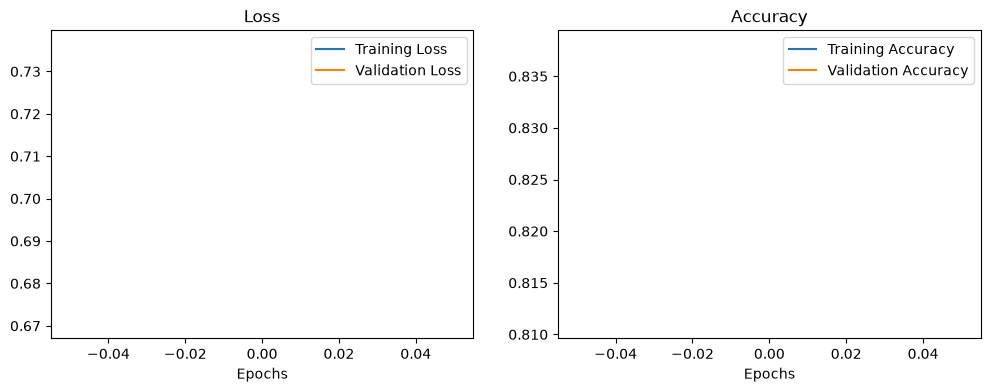

In [10]:
history = train_and_evaluate(
    model, train_data, test_data, epochs=1
)

## Stage 4: Evaluate and visualize predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step


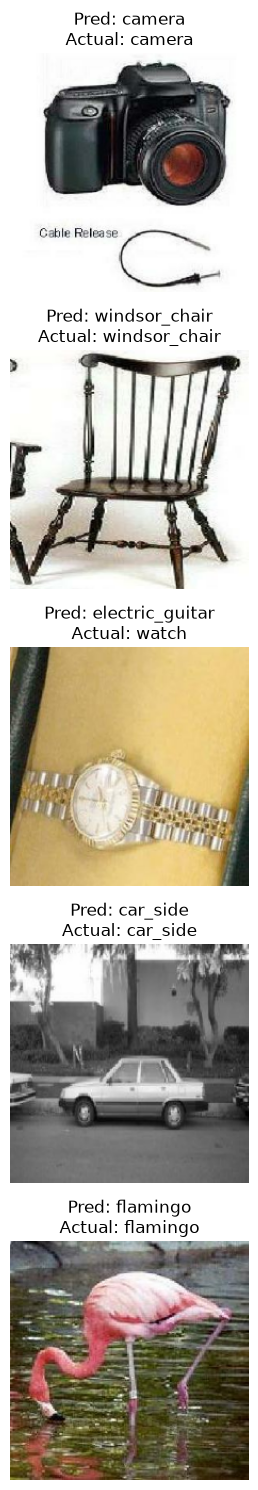

In [13]:
show_prediction(model, test_data, class_names)

## Stage 5: Fine-tune the last VGG16 layers

In [ ]:
fine_tune(
    model, base_model, train_data, test_data, epochs=1
)

# 5B. Transfer Learning – Intel Image Classification

## Stage 1: Load and preprocess the data

Download and extract the Intel Image Classification dataset. Set `DATASET_PATH` to its extracted folder. The expected structure is:

- `seg_train/seg_train/` – training class folders
- `seg_test/seg_test/` – testing class folders

If your extracted folder has a different layout, adjust the two paths.

In [3]:
DATASET_PATH = 'dataset/object/intel'
IMAGE_SIZE = (224, 224)
BATCH_SIZE=32

train_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset='training',
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

test_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

class_names = train_data.class_names
number_of_classes = len(class_names)

print("Number of classes:", number_of_classes)
print("Classes:", class_names)

Found 12632 files belonging to 6 classes.
Using 10106 files for training.


E0000 00:00:1793727163.112472   13232 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 12632 files belonging to 6 classes.
Using 2526 files for validation.
Number of classes: 6
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## Stage 2: Choose the pre-trained model and add classification layers

In [4]:
model, base_model = build_model(number_of_classes)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,126 (56.39 MB)

 Trainable params: 66,438 (259.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## Stage 3: Train with frozen VGG16 layers

/home/michey/Downloads/practical/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


316/316 ━━━━━━━━━━━━━━━━━━━━ 1121s 4s/step - accuracy: 0.8613 - loss: 0.4817 - val_accuracy: 0.9058 - val_loss: 0.2908
79/79 ━━━━━━━━━━━━━━━━━━━━ 246s 3s/step - accuracy: 0.9058 - loss: 0.2908
Test Loss: 0.2908240556716919
Test Accuracy: 0.9057798981666565


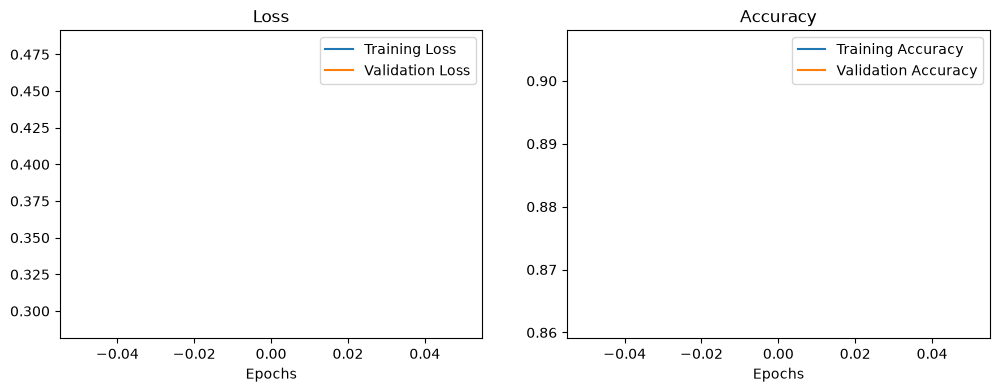

In [7]:
history = train_and_evaluate(
    model, train_data, test_data, epochs=1
)

## Stage 4: Evaluate and visualize predictions

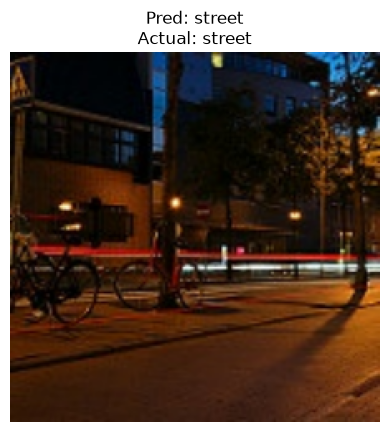

In [10]:
show_prediction(model, test_data, class_names)

## Stage 5: Fine-tune the last VGG16 layers

In [ ]:
fine_tune(
    model, base_model, train_data, test_data, epochs=1
)

# 5C. Transfer Learning – Fashion MNIST

## Stage 1: Load and preprocess the data

Fashion MNIST contains 28 × 28 grayscale images. VGG16 expects 224 × 224 RGB images, so we convert grayscale images to three channels and resize them inside the model.

In [11]:
DATASET_PATH = 'dataset/object/fashion'
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset='training',
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='int'
)

test_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='int'
)

number_of_classes = len(train_data.class_names)

print("Classes:", train_data.class_names)
print("Number of classes:", number_of_classes)

Found 12832 files belonging to 11 classes.
Using 10266 files for training.
Found 12832 files belonging to 11 classes.
Using 2566 files for validation.
Classes: ['Ankle-boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt-top', 'Trouser', 'train']
Number of classes: 11


## Stage 2: Choose the pre-trained model and add classification layers

In [12]:
model, base_model = build_model(number_of_classes)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,771 (56.39 MB)

 Trainable params: 67,083 (262.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## Stage 3: Train with frozen VGG16 layers

321/321 ━━━━━━━━━━━━━━━━━━━━ 1094s 3s/step - accuracy: 0.7621 - loss: 0.7733 - val_accuracy: 0.7907 - val_loss: 0.5993
81/81 ━━━━━━━━━━━━━━━━━━━━ 232s 3s/step - accuracy: 0.7907 - loss: 0.5993
Test Loss: 0.5993450284004211
Test Accuracy: 0.7907248735427856


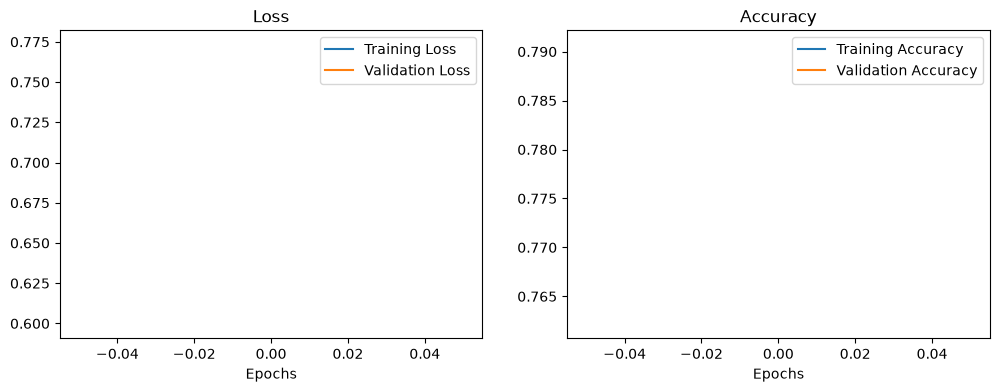

In [13]:
history = train_and_evaluate(
    model, train_data, test_data, epochs=1
)

## Stage 4: Evaluate and visualize predictions

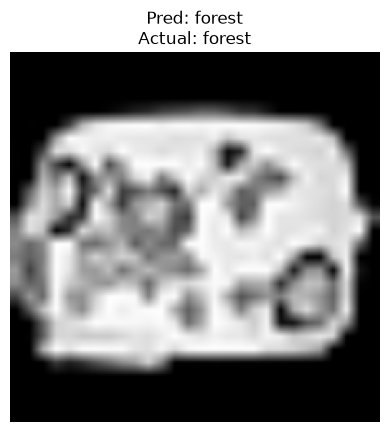

In [15]:
show_prediction(model, test_data, class_names)

## Stage 5: Fine-tune the last VGG16 layers

In [17]:
fine_tune(
    model, base_model, train_data, test_data, epochs=1
)

  5/321 ━━━━━━━━━━━━━━━━━━━━ 18:32 4s/step - accuracy: 0.5500 - loss: 1.5099

KeyboardInterrupt: 